In [1]:
import sys
sys.path.append('..')

import matplotlib.pyplot as plt
from models import XGBClf
from load_kids_catalog import load_and_process, concat_two_catalogs
from data_exp import ExperimentalData
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

#### Load data

In [2]:
data = ExperimentalData(concat_two_catalogs(load_and_process('../data/KiDS_DR5_WCScut_x_DESI_DR1_columns.csv'), load_and_process('../data/KiDS_DR5_WCScut_x_SDSS_DR17_columns.csv')))

X_test, y_test = data.get_test_clf()

DataFrame shape: (1947376, 61)
DataFrame shape: (137094, 61)


#### Load Model

In [3]:
model = XGBClf()
model.load('../saved_models/classification/xgb_clf_2026-10-09T14-12-49Z.json')

#### Evaluate

              precision    recall  f1-score   support

           0       0.98      0.99      0.99     31410
           1       0.98      0.99      0.98    154652
           2       0.90      0.77      0.83     12677

    accuracy                           0.98    198739
   macro avg       0.95      0.92      0.93    198739
weighted avg       0.98      0.98      0.98    198739



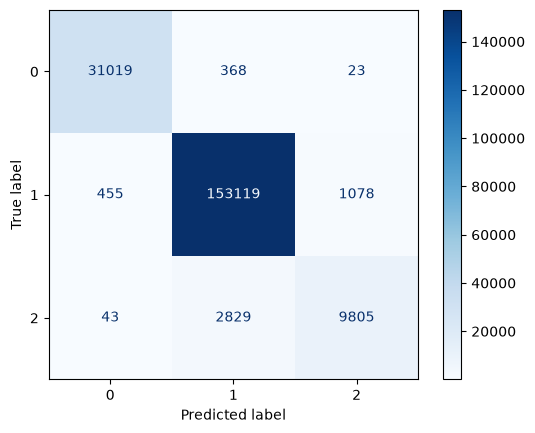

In [4]:
test_preds = model.predict(X_test)
print(classification_report(y_test, test_preds))

ConfusionMatrixDisplay.from_predictions(y_test, test_preds, cmap='Blues')
plt.show()